# Partie 2 — Transfer learning et choix d'architecture sous contrainte

**Projet DiagnoCulture** — diagnostic des maladies de la tomate (10 classes, PlantVillage).

On réutilise le découpage figé de la Partie 1 (`split.csv`) mais on passe à des **backbones pré-entraînés sur ImageNet** (`torchvision.models`), adaptés à nos 10 classes, en **160×160** avec la **normalisation ImageNet**.

**Plan.** (1) Setup · (2) Données · (3) Backbones pré-entraînés (MobileNetV2 + ResNet-50) · (4) Trois stratégies de transfert · (5) Évaluation sur le test · (6) Front de Pareto & recommandation.

> Le jeu de **test ne sert qu'une seule fois** par modèle final. Toute sélection se fait sur la **validation**.

## 1. Setup

**Tous les imports sont regroupés dans la cellule ci-dessous.**

In [1]:
# =========================================================
#  IMPORTS (tous regroupes ici)
# =========================================================
!pip install -q torchinfo

import os, json, copy, time, random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models        # 'models' = les backbones pre-entraines

from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from torchinfo import summary

import kagglehub
from google.colab import drive

**Reproductibilité + device.** On fixe les graines (Python, NumPy, PyTorch, cuDNN déterministe) et on sélectionne le GPU si disponible.

In [2]:
def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)   # attendu : cuda

device: cuda


**Montage de Drive (stockage persistant) et téléchargement du dataset via kagglehub.** Le cache kagglehub est temporaire ; seul Drive persiste d'une session à l'autre.

In [3]:
drive.mount('/content/drive')

ROOT    = "/content/drive/MyDrive/Project_clean"
DATA    = os.path.join(ROOT, "data")       # split.csv
MODELS  = os.path.join(ROOT, "models")     # .pt
RESULTS = os.path.join(ROOT, "results")    # figures .png + .csv
for d in (DATA, MODELS, RESULTS): os.makedirs(d, exist_ok=True)



Mounted at /content/drive


In [4]:


base = kagglehub.dataset_download("emmarex/plantdisease")
print("Dataset :", base)

Using Colab cache for faster access to the 'plantdisease' dataset.
Dataset : /kaggle/input/plantdisease


**Racine des classes** (`.../PlantVillage/Tomato…`) et liste triée des 10 classes.

In [5]:
DATA_ROOT = None
for r, d, _ in os.walk(base):
    if any(x.startswith("Tomato") for x in d):
        DATA_ROOT = r
        break

classes = sorted(c for c in os.listdir(DATA_ROOT) if c.startswith("Tomato"))
print("DATA_ROOT =", DATA_ROOT)
print(len(classes), "classes")   # attendu : 10

DATA_ROOT = /kaggle/input/plantdisease/PlantVillage
10 classes


**Rechargement du découpage figé** (`split.csv`) — même split 70/15/15 (seed 42) que la Partie 1, donc résultats directement comparables.

In [6]:
clean_data = pd.read_csv(os.path.join(DATA, "split.csv"))
print(clean_data.shape)                       # attendu : (15997, ...)
print(clean_data["split"].value_counts())     # train 11197 / val 2400 / test 2400

(15997, 4)
split
train    11197
test      2400
val       2400
Name: count, dtype: int64


## 2. Données

**Deux différences avec la Partie 1 :** résolution **160×160** (au lieu de 128) et **normalisation ImageNet** (au lieu des stats PlantVillage).

> **Pourquoi la normalisation ImageNet ?** Les backbones sont pré-entraînés sur ImageNet ; leurs premières couches attendent des entrées normalisées avec les statistiques ImageNet (`mean=[0.485,0.456,0.406]`, `std=[0.229,0.224,0.225]`). Normaliser avec les stats PlantVillage décalerait la distribution d'entrée vue par le réseau pré-entraîné et dégraderait l'extraction de features dès la première couche. Règle : **on reprend le prétraitement du pré-entraînement.**

In [7]:
# --- LeafDataset
IMG = 160                                    # resolution transfer learning
IMAGENET_MEAN = [0.485, 0.456, 0.406]        # stats du jeu ImageNet (pas PlantVillage)
IMAGENET_STD  = [0.229, 0.224, 0.225]

class LeafDataset(Dataset):
    def __init__(self, df, split, img_size, mean, std, augment=False):
        self.df = df[df["split"] == split].reset_index(drop=True)
        tfms = [transforms.Resize((img_size, img_size))]
        if augment:                          # miroir horizontal : train uniquement
            tfms += [transforms.RandomHorizontalFlip()]
        tfms += [transforms.ToTensor(), transforms.Normalize(mean, std)]
        self.tf = transforms.Compose(tfms)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(os.path.join(DATA_ROOT, row["path"])).convert("RGB")
        return self.tf(img), int(row["class_idx"])

**`Dataset` + `DataLoader`** (augmentation — miroir horizontal — sur le train uniquement).

In [8]:
# DataLoaders + vérif d’un batch
train_ds = LeafDataset(clean_data, "train", IMG, IMAGENET_MEAN, IMAGENET_STD, augment=True)
val_ds   = LeafDataset(clean_data, "val",   IMG, IMAGENET_MEAN, IMAGENET_STD, augment=False)
test_ds  = LeafDataset(clean_data, "test",  IMG, IMAGENET_MEAN, IMAGENET_STD, augment=False)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

images, labels = next(iter(train_loader))
print(images.shape, labels.shape)   # attendu : [32, 3, 160, 160] [32]

torch.Size([32, 3, 160, 160]) torch.Size([32])


**Résultat.** Un batch sort en `[32, 3, 160, 160]` : format `(N, C, H, W)` attendu par les backbones.

## 3. Modèles pré-entraînés

**Choix des deux backbones (justification via le cours).**

On sélectionne deux réseaux pré-entraînés sur ImageNet aux philosophies opposées :

- **MobileNetV2 (léger, ~2,2 M params).** Idée-clé : les **convolutions séparables en profondeur** (depthwise + pointwise) qui factorisent filtrage spatial et combinaison de canaux, divisant le coût de calcul par ~8-9× à capacité comparable ; et les **blocs résiduels inversés** (expansion 1×1 → depthwise 3×3 → projection 1×1, raccourci entre les couches étroites). Conçu pour l'embarqué → pertinent pour notre cible « smartphone ».
- **ResNet-50 (lourd, ~23,5 M params).** Idée-clé : les **connexions résiduelles** profondes (50 couches) qui, via le raccourci identité, évitent le vanishing gradient et permettent d'empiler beaucoup de couches pour une précision maximale. ResNet est explicitement traité en cours ; notre diagnostic de gradients (Partie 1) motive son intérêt en profondeur.

Ce couple léger/lourd alimente le front de Pareto (précision vs latence) et la recommandation de déploiement.

**Fabrique de modèles.** On charge les poids ImageNet et on remplace la **tête** de classification (1000 classes ImageNet → 10 classes tomate). MobileNetV2 range sa tête dans `classifier[1]`, ResNet-50 dans `fc`.

In [9]:
def build_mobilenet_v2(num_classes=10):
    m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)   # 1280 -> 10
    return m

def build_resnet50(num_classes=10):
    m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    m.fc = nn.Linear(m.fc.in_features, num_classes)                         # 2048 -> 10
    return m

# verif des tetes remplacees
_m, _r = build_mobilenet_v2(), build_resnet50()
print("MobileNetV2 tete :", _m.classifier[1])
print("ResNet-50   tete :", _r.fc)
del _m, _r

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 150MB/s]


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 142MB/s]


MobileNetV2 tete : Linear(in_features=1280, out_features=10, bias=True)
ResNet-50   tete : Linear(in_features=2048, out_features=10, bias=True)


**Nombre de paramètres et taille mémoire** des deux backbones.

In [10]:
def count_params(model):
    return sum(p.numel() for p in model.parameters())

def size_mb(model):
    return count_params(model) * 4 / 1e6        # float32 = 4 octets/param

for name, m in [("MobileNetV2", build_mobilenet_v2()), ("ResNet-50", build_resnet50())]:
    print(f"{name:12s} : {count_params(m)/1e6:5.2f} M params | ~{size_mb(m):5.1f} Mo")

MobileNetV2  :  2.24 M params | ~  8.9 Mo
ResNet-50    : 23.53 M params | ~ 94.1 Mo


**Résultat.** MobileNetV2 ≈ **2,24 M (~8,9 Mo)**, ResNet-50 ≈ **23,5 M (~94 Mo)** — soit ~10× plus lourd. L'écart léger/lourd est posé ; il nourrira le Pareto. (MobileNetV2 est plus petit que ses ~3,5 M « officiels » car notre tête 10 classes est minuscule face à la tête 1000 classes d'origine.)

**Helper de latence (CPU + GPU).** Latence moyenne par image (batch=1, moyenne sur 120 passes + warm-up). La latence batch=1 reflète le cas réel « une photo à la fois » sur un téléphone. On imprime aussi la **machine** (GPU + cœurs CPU), comme demandé par la consigne.

In [11]:
@torch.no_grad()
def measure_latency_ms(model, dev, img_size=IMG, n=120, warmup=10):
    """Latence moyenne par image (ms), batch=1, sur le device demande."""
    model = model.to(dev).eval()
    x = torch.randn(1, 3, img_size, img_size, device=dev)
    for _ in range(warmup):                      # rodage (alloc memoire, cache)
        model(x)
    if dev.type == "cuda":
        torch.cuda.synchronize()                 # on attend la fin reelle du GPU
    t0 = time.time()
    for _ in range(n):
        model(x)
    if dev.type == "cuda":
        torch.cuda.synchronize()
    return (time.time() - t0) / n * 1000.0

cpu = torch.device("cpu")
gpu = device
# le prof demande de PRECISER LA MACHINE :
print("GPU :", torch.cuda.get_device_name(0) if gpu.type == "cuda" else "aucun")
print("CPU :", os.cpu_count(), "coeurs logiques")

GPU : Tesla T4
CPU : 2 coeurs logiques


## 4. Fine-tuning — les trois stratégies

On compare trois façons d'exploiter un backbone pré-entraîné :
- **(a) extraction de features** : backbone **gelé**, on n'entraîne que la tête ;
- **(b) fine-tuning des dernières couches** : on dégèle les derniers blocs de l'extracteur + la tête ;
- **(c) fine-tuning complet, lr différencié** : tout apprend, mais avec un **petit lr** sur le backbone et un **grand lr** sur la tête neuve.

Les trois stratégies sont appliquées à **MobileNetV2** ; **ResNet-50** sert de 2ᵉ backbone sur la stratégie (a).

**Fonction d'entraînement générique** (train/val + early-stopping, comme en Partie 1). Nouveauté : l'optimiseur reçoit des **groupes de paramètres** (`param_groups`), ce qui permet des learning rates distincts pour la stratégie (c). Elle sauve le meilleur modèle sur Drive et chronomètre le temps d'entraînement.

In [16]:
def train_model(model, param_groups, epochs=10, patience=3, tag="model", seed=42):
    set_seed(seed)
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(param_groups)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}   # <<< train_acc ajoute
    best_val, best_weights, patience_cnt = float("inf"), copy.deepcopy(model.state_dict()), 0
    t_start = time.time()

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        model.train(); running = 0.0; tr_correct = 0; tr_total = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)                                    # <<< reutilise 'out'
            loss.backward(); optimizer.step()
            running += loss.item() * x.size(0)
            tr_correct += (out.argmax(1) == y).sum().item(); tr_total += y.size(0)
        train_loss = running / len(train_loader.dataset)
        train_acc  = tr_correct / tr_total

        model.eval(); vrun, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                out = model(x)
                vrun    += criterion(out, y).item() * x.size(0)
                correct += (out.argmax(1) == y).sum().item()
                total   += y.size(0)
        val_loss, val_acc = vrun / len(val_loader.dataset), correct / total

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        print(f"[{tag}] ep {epoch:2d} | train {train_loss:.4f} (acc {train_acc:.3f}) | val {val_loss:.4f} | val_acc {val_acc:.3f} | {time.time()-t0:.0f}s")

        if val_loss < best_val:
            best_val, best_weights, patience_cnt = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            patience_cnt += 1
            if patience_cnt >= patience:
                print(f"[{tag}] early-stopping ep {epoch}")
                break

    model.load_state_dict(best_weights)
    torch.save(best_weights, os.path.join(MODELS, f"tl_{tag}_best.pt"))
    history["train_minutes"] = (time.time() - t_start) / 60.0
    history["best_val_loss"] = best_val
    print(f"[{tag}] fini en {history['train_minutes']:.1f} min | best val_loss {best_val:.4f}")
    return model, history

**Helpers de gel.** `requires_grad = False` = « ne pas calculer le gradient, ne pas modifier » (= geler). On ne met dans l'optimiseur que ce qui reste entraînable.

In [17]:
def freeze_all(model):
    for p in model.parameters():
        p.requires_grad = False

def set_requires_grad(module, flag=True):
    for p in module.parameters():
        p.requires_grad = flag

def trainable_params(model):
    return [p for p in model.parameters() if p.requires_grad]

### (a) Extraction de features — backbone gelé (MobileNetV2)

Tout le backbone est gelé (les filtres ImageNet ne bougent pas), on n'entraîne que la tête `Linear(1280→10)`. C'est la définition du transfer learning du cours : très rapide, peu de risque de sur-apprentissage. C'est notre **baseline** de transfert.

In [18]:
results_hist = {}        # tag -> courbes
models_store = {}        # tag -> modele entraine (pour l'eval du §5)

m = build_mobilenet_v2()
freeze_all(m)                              # backbone ET tete geles...
set_requires_grad(m.classifier, True)      # ...puis on REOUVRE seulement la tete
pg = [{"params": trainable_params(m), "lr": 1e-3}]
m, h = train_model(m, pg, epochs=8, patience=3, tag="mbv2_feat")
models_store["mbv2_feat"], results_hist["mbv2_feat"] = m, h

[mbv2_feat] ep  1 | train 0.7185 (acc 0.780) | val 0.3612 | val_acc 0.892 | 30s
[mbv2_feat] ep  2 | train 0.3894 (acc 0.874) | val 0.2785 | val_acc 0.911 | 30s
[mbv2_feat] ep  3 | train 0.3449 (acc 0.886) | val 0.2679 | val_acc 0.917 | 30s
[mbv2_feat] ep  4 | train 0.3101 (acc 0.898) | val 0.2382 | val_acc 0.920 | 30s
[mbv2_feat] ep  5 | train 0.2898 (acc 0.905) | val 0.2131 | val_acc 0.926 | 30s
[mbv2_feat] ep  6 | train 0.2845 (acc 0.904) | val 0.2294 | val_acc 0.922 | 30s
[mbv2_feat] ep  7 | train 0.2720 (acc 0.906) | val 0.2120 | val_acc 0.929 | 30s
[mbv2_feat] ep  8 | train 0.2684 (acc 0.908) | val 0.2127 | val_acc 0.928 | 30s
[mbv2_feat] fini en 4.0 min | best val_loss 0.2120


**Interprétation.** La `val_acc` plafonne vite autour de **0,93** — en dessous du CNN-Plain de la Partie 1 (0,960). Normal : les features ImageNet **gelées** sont génériques (chats, voitures…) et pas optimales sur des feuilles de labo. Le fine-tuning va corriger ça.

### (b) Fine-tuning des dernières couches (MobileNetV2)

`features` de MobileNetV2 a 19 blocs (0→18). On garde gelés les premiers (bords, textures génériques, utiles partout) et on rouvre les **derniers** (`[14:]`, motifs les plus spécifiques) **+ la tête**. lr un peu plus petit (`5e-4`) car on touche des poids déjà bons.

In [19]:
m = build_mobilenet_v2()
freeze_all(m)
set_requires_grad(m.features[14:], True)   # on degele les DERNIERS blocs de l'extracteur
set_requires_grad(m.classifier, True)      # + la tete
n_tr = sum(p.numel() for p in trainable_params(m))
print(f"entrainables : {n_tr/1e6:.2f} M / {count_params(m)/1e6:.2f} M")
pg = [{"params": trainable_params(m), "lr": 5e-4}]
m, h = train_model(m, pg, epochs=10, patience=3, tag="mbv2_ftlast")
models_store["mbv2_ftlast"], results_hist["mbv2_ftlast"] = m, h

entrainables : 1.69 M / 2.24 M
[mbv2_ftlast] ep  1 | train 0.2828 (acc 0.905) | val 0.1114 | val_acc 0.959 | 31s
[mbv2_ftlast] ep  2 | train 0.1165 (acc 0.960) | val 0.0838 | val_acc 0.975 | 30s
[mbv2_ftlast] ep  3 | train 0.0823 (acc 0.974) | val 0.0719 | val_acc 0.975 | 30s
[mbv2_ftlast] ep  4 | train 0.0695 (acc 0.976) | val 0.0530 | val_acc 0.983 | 30s
[mbv2_ftlast] ep  5 | train 0.0545 (acc 0.982) | val 0.0363 | val_acc 0.989 | 30s
[mbv2_ftlast] ep  6 | train 0.0431 (acc 0.986) | val 0.0535 | val_acc 0.984 | 30s
[mbv2_ftlast] ep  7 | train 0.0554 (acc 0.981) | val 0.0418 | val_acc 0.986 | 30s
[mbv2_ftlast] ep  8 | train 0.0488 (acc 0.984) | val 0.0471 | val_acc 0.984 | 30s
[mbv2_ftlast] early-stopping ep 8
[mbv2_ftlast] fini en 4.0 min | best val_loss 0.0363


**Interprétation.** Gros bond : **val_acc ≈ 0,99** en ne réentraînant que ~1,7 M / 2,24 M de paramètres. Dès qu'on spécialise les derniers blocs « feuilles », on dépasse même le CNN-Plain. Confirme que **geler ≠ suffisant**.

### (c) Fine-tuning complet, learning rate différencié (MobileNetV2)

Tout le réseau apprend, mais avec **deux lr** (c'est l'intérêt des `param_groups`) : **petit lr (1e-4)** sur le backbone pré-entraîné pour l'ajuster sans détruire ce qu'il sait, **grand lr (1e-3)** sur la tête neuve pour qu'elle apprenne vite. C'est le *discriminative fine-tuning* standard.

In [20]:
m = build_mobilenet_v2()                    # TOUT est entrainable (pas de gel)
pg = [
    {"params": m.features.parameters(),   "lr": 1e-4},   # backbone : PETIT lr
    {"params": m.classifier.parameters(), "lr": 1e-3},   # tete neuve : GRAND lr
]
m, h = train_model(m, pg, epochs=8, patience=3, tag="mbv2_full")
models_store["mbv2_full"], results_hist["mbv2_full"] = m, h

[mbv2_full] ep  1 | train 0.2880 (acc 0.905) | val 0.0674 | val_acc 0.978 | 36s
[mbv2_full] ep  2 | train 0.0685 (acc 0.976) | val 0.0611 | val_acc 0.983 | 36s
[mbv2_full] ep  3 | train 0.0495 (acc 0.983) | val 0.0601 | val_acc 0.981 | 36s
[mbv2_full] ep  4 | train 0.0419 (acc 0.986) | val 0.0669 | val_acc 0.982 | 36s
[mbv2_full] ep  5 | train 0.0393 (acc 0.987) | val 0.0702 | val_acc 0.981 | 36s
[mbv2_full] ep  6 | train 0.0306 (acc 0.990) | val 0.0560 | val_acc 0.988 | 36s
[mbv2_full] ep  7 | train 0.0384 (acc 0.988) | val 0.0645 | val_acc 0.983 | 36s
[mbv2_full] ep  8 | train 0.0256 (acc 0.990) | val 0.0453 | val_acc 0.989 | 36s
[mbv2_full] fini en 4.8 min | best val_loss 0.0453


**Interprétation.** Meilleur modèle : **val_acc ≈ 0,99 / val_loss la plus basse**. Niveau équivalent à (b) pour un peu plus de calcul → en pratique, **(b) ≈ (c)** : fine-tuner les dernières couches suffit presque.

### ResNet-50 — extraction de features (2ᵉ backbone)

Même stratégie (a), mais sur le backbone **lourd**. Objectif : avoir un point **ResNet-50** sur le Pareto et comparer léger vs lourd (ce n'est pas une 4ᵉ stratégie).

In [21]:
m = build_resnet50()
freeze_all(m)
set_requires_grad(m.fc, True)               # ResNet range sa tete dans .fc
pg = [{"params": trainable_params(m), "lr": 1e-3}]
m, h = train_model(m, pg, epochs=8, patience=3, tag="r50_feat")
models_store["r50_feat"], results_hist["r50_feat"] = m, h

[r50_feat] ep  1 | train 0.9735 (acc 0.740) | val 0.5776 | val_acc 0.858 | 37s
[r50_feat] ep  2 | train 0.4895 (acc 0.875) | val 0.3967 | val_acc 0.891 | 36s
[r50_feat] ep  3 | train 0.3740 (acc 0.902) | val 0.3476 | val_acc 0.901 | 36s
[r50_feat] ep  4 | train 0.3155 (acc 0.914) | val 0.3106 | val_acc 0.911 | 36s
[r50_feat] ep  5 | train 0.2789 (acc 0.922) | val 0.2832 | val_acc 0.919 | 36s
[r50_feat] ep  6 | train 0.2414 (acc 0.937) | val 0.2612 | val_acc 0.920 | 36s
[r50_feat] ep  7 | train 0.2271 (acc 0.937) | val 0.2436 | val_acc 0.923 | 36s
[r50_feat] ep  8 | train 0.2070 (acc 0.945) | val 0.2488 | val_acc 0.928 | 36s
[r50_feat] fini en 4.8 min | best val_loss 0.2436


**Interprétation.** ResNet-50 **gelé** atteint ~0,93 en val, comme MobileNetV2 gelé : en features pures, le gros backbone n'apporte pas d'avantage ici (et il descendait encore à l'époque 8 — on garde 8 pour comparer à budget égal).

**Courbes d'apprentissage des 4 entraînements** (loss train/val).

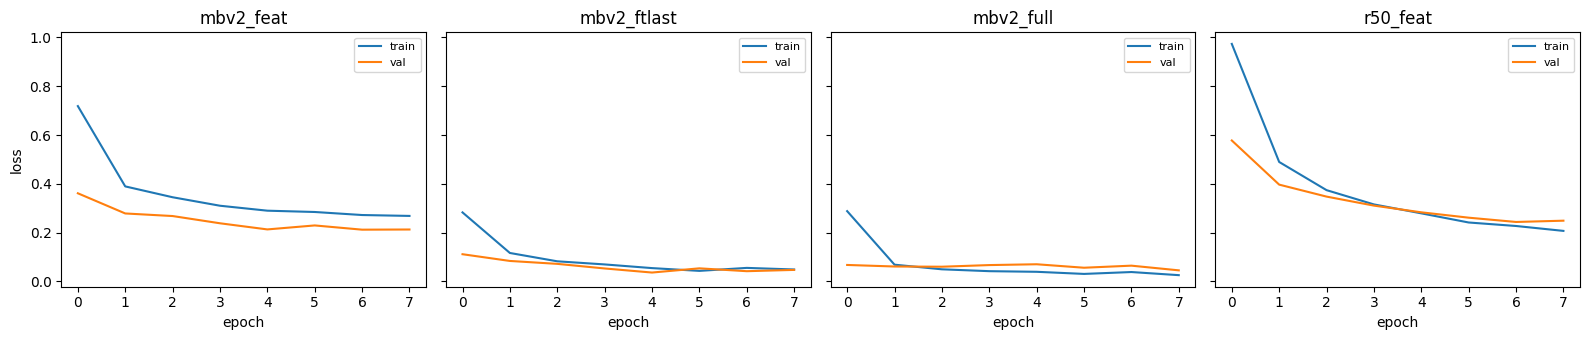

In [22]:
order = ["mbv2_feat", "mbv2_ftlast", "mbv2_full", "r50_feat"]
fig, axes = plt.subplots(1, len(order), figsize=(4*len(order), 3.5), sharey=True)
for ax, tag in zip(axes, order):
    h = results_hist[tag]
    ax.plot(h["train_loss"], label="train")
    ax.plot(h["val_loss"],   label="val")
    ax.set_title(tag); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
axes[0].set_ylabel("loss")
plt.tight_layout(); plt.show()

**Interprétation.** (a) et r50_feat plafonnent haut (loss 0,2) ; (b) et (c) descendent bien plus bas (0,05) avec un faible écart train/val → pas de sur-apprentissage marqué.

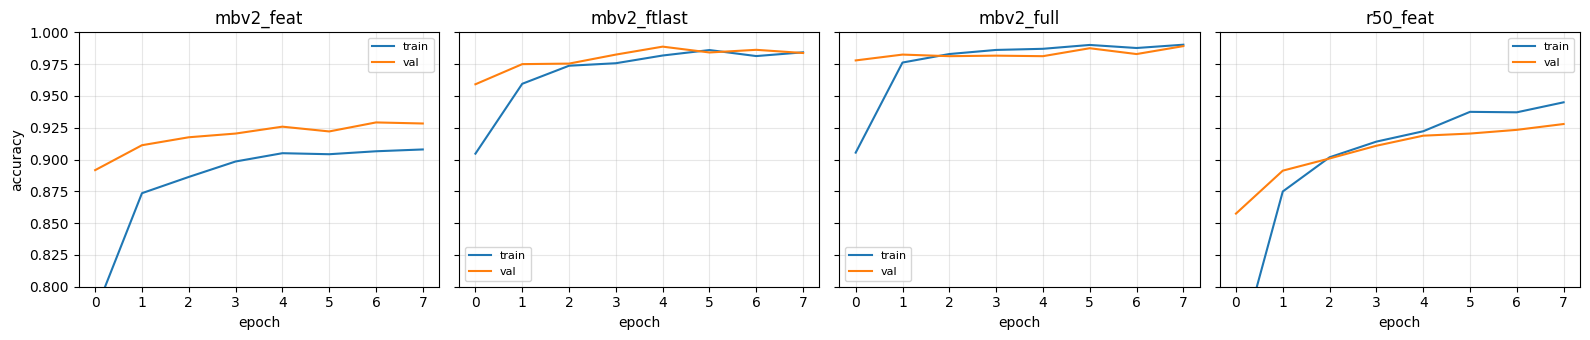

In [23]:
fig, axes = plt.subplots(1, len(order), figsize=(4*len(order), 3.5), sharey=True)
for ax, tag in zip(axes, order):
    h = results_hist[tag]
    ax.plot(h["train_acc"], label="train")
    ax.plot(h["val_acc"],   label="val")
    ax.set_title(tag); ax.set_xlabel("epoch"); ax.set_ylim(0.80, 1.0)
    ax.grid(True, alpha=.3); ax.legend(fontsize=8)
axes[0].set_ylabel("accuracy")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS, "tl_acc_curves.png"), dpi=120, bbox_inches="tight"); plt.show()

## 5. Évaluation (test)

**Évaluation unique sur le test** de chaque modèle (accuracy, F1-macro), avec mesure des params / taille / latence CPU & GPU pour le tableau récap. La latence CPU est un peu lente (2 cœurs) — c'est normal.

In [24]:
@torch.no_grad()
def evaluate(model):
    model = model.to(device).eval()
    y_true, y_pred = [], []
    for x, y in test_loader:
        out = model(x.to(device))
        y_pred += out.argmax(1).cpu().tolist()
        y_true += y.tolist()
    acc = accuracy_score(y_true, y_pred)
    f1m = f1_score(y_true, y_pred, average="macro")
    return acc, f1m, y_true, y_pred

LABELS = {
    "mbv2_feat":   "MobileNetV2 - (a) extraction",
    "mbv2_ftlast": "MobileNetV2 - (b) fine-tune dern. couches",
    "mbv2_full":   "MobileNetV2 - (c) fine-tune complet (lr diff.)",
    "r50_feat":    "ResNet-50 - (a) extraction",
}
order = ["mbv2_feat", "mbv2_ftlast", "mbv2_full", "r50_feat"]

rows, preds = [], {}
for tag in order:
    model = models_store[tag]
    acc, f1m, yt, yp = evaluate(model)
    preds[tag] = (yt, yp)
    lat_gpu = measure_latency_ms(model, gpu) if gpu.type == "cuda" else float("nan")
    lat_cpu = measure_latency_ms(model, cpu)
    model.to(device)                                   # on remet sur GPU apres la mesure CPU
    rows.append({
        "tag": tag, "modele": LABELS[tag],
        "params_M": round(count_params(model)/1e6, 2),
        "taille_Mo": round(size_mb(model), 1),
        "lat_CPU_ms": round(lat_cpu, 1),
        "lat_GPU_ms": round(lat_gpu, 2),
        "acc": round(acc, 4), "f1_macro": round(f1m, 4),
        "min_train": round(results_hist[tag]["train_minutes"], 1),
    })
    print(f"{LABELS[tag]:46s} | acc {acc:.3f} | F1m {f1m:.3f} | CPU {lat_cpu:5.1f} ms | GPU {lat_gpu:4.2f} ms")

MobileNetV2 - (a) extraction                   | acc 0.929 | F1m 0.916 | CPU  14.0 ms | GPU 5.16 ms
MobileNetV2 - (b) fine-tune dern. couches      | acc 0.988 | F1m 0.985 | CPU  13.7 ms | GPU 5.13 ms
MobileNetV2 - (c) fine-tune complet (lr diff.) | acc 0.991 | F1m 0.992 | CPU  13.9 ms | GPU 5.10 ms
ResNet-50 - (a) extraction                     | acc 0.919 | F1m 0.904 | CPU  64.2 ms | GPU 5.39 ms


**Interprétation (test).**

| modèle | stratégie | acc | F1-macro | lat CPU | lat GPU |
|---|---|---|---|---|---|
| MobileNetV2 (c) complet | fine-tune lr diff. | 0,991 | **0,992** | 13,9 ms | 5,1 ms |
| MobileNetV2 (b) dern. couches | fine-tune partiel | 0,988 | 0,985 | 13,7 ms | 5,1 ms |
| MobileNetV2 (a) extraction | gelé | 0,929 | 0,916 | 14,0 ms | 5,2 ms |
| ResNet-50 (a) extraction | gelé, lourd | 0,919 | 0,904 | 64,2 ms | 5,4 ms |

Le **fine-tuning complet de MobileNetV2** est le meilleur (F1 0,992), devant les CNN maison de la Partie 1. ResNet-50 gelé est le pire **et** ~4,6× plus lent sur CPU.

**Rapport par classe + matrice de confusion du meilleur modèle.**

Meilleur modele : MobileNetV2 - (c) fine-tune complet (lr diff.)
                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot      0.994     0.972     0.983       319
                        Tomato_Early_blight      0.980     0.987     0.983       150
                         Tomato_Late_blight      0.996     0.993     0.995       285
                           Tomato_Leaf_Mold      1.000     0.993     0.996       143
                  Tomato_Septoria_leaf_spot      0.996     0.992     0.994       266
Tomato_Spider_mites_Two_spotted_spider_mite      0.988     0.996     0.992       251
                        Tomato__Target_Spot      0.995     0.995     0.995       211
      Tomato__Tomato_YellowLeaf__Curl_Virus      0.980     0.998     0.989       481
                Tomato__Tomato_mosaic_virus      1.000     0.982     0.991        56
                             Tomato_healthy      1.000     0.996     0.998       238

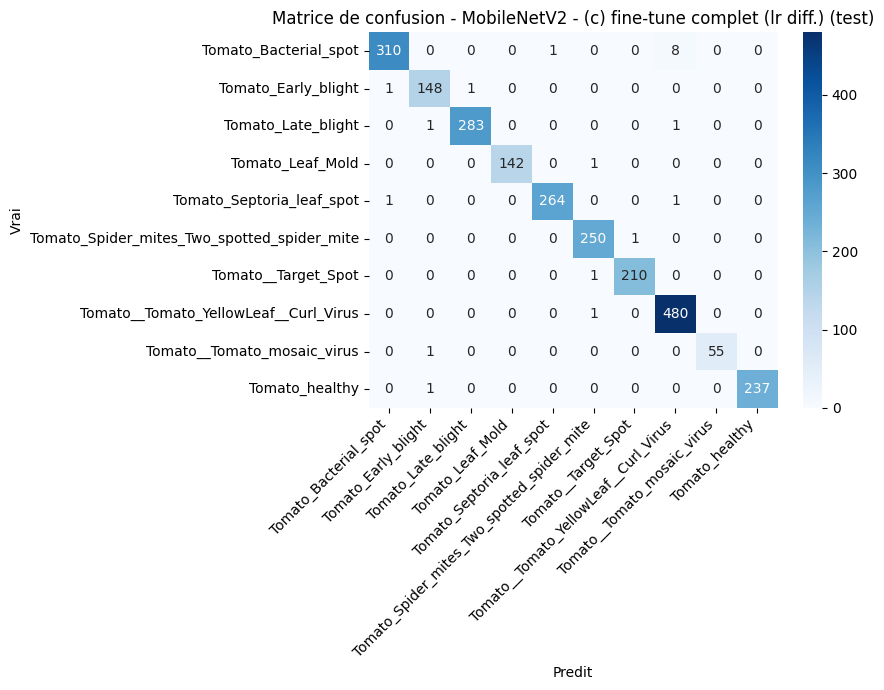

In [25]:
best_tag = max(order, key=lambda t: dict((r["tag"], r["f1_macro"]) for r in rows)[t])
yt, yp = preds[best_tag]
print("Meilleur modele :", LABELS[best_tag])
print(classification_report(yt, yp, target_names=classes, digits=3))

cm = confusion_matrix(yt, yp)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predit"); plt.ylabel("Vrai")
plt.title(f"Matrice de confusion - {LABELS[best_tag]} (test)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig(os.path.join(RESULTS, "tl_confusion_best.png"), dpi=120, bbox_inches="tight")
plt.show()

**Interprétation.** F1-macro 0,992, aucune classe sous 0,98 malgré le déséquilibre (mosaic_virus, 56 images test → F1 0,991). Seule confusion notable : **8 _Bacterial_spot_ prédits _YellowLeaf_Curl_** (classe la plus fréquente + jaunissement foliaire visuellement proche) — différent de la Partie 1 (Early↔Late blight).

## 6. Résultat consigné — tableau, front de Pareto, recommandation

**Réintégration de CNN-Plain / CNN-Res (Partie 1) pour le Pareto.** Leur **accuracy** vient de la Partie 1 ; leur **latence** est mesurée ici à 128×128 (leur résolution d'exploitation). La latence ne dépend pas des poids → on instancie les architectures sans recharger les `.pt`.

In [26]:
# Architectures Partie 1 (copie minimale) : on mesure leur latence a 128px.
# La latence ne depend PAS des poids -> pas besoin de recharger les .pt.
class CNNPlain(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.conv1=nn.Conv2d(3,32,3,padding=1);   self.bn1=nn.BatchNorm2d(32)
        self.conv2=nn.Conv2d(32,64,3,padding=1);  self.bn2=nn.BatchNorm2d(64)
        self.conv3=nn.Conv2d(64,128,3,padding=1); self.bn3=nn.BatchNorm2d(128)
        self.conv4=nn.Conv2d(128,128,3,padding=1);self.bn4=nn.BatchNorm2d(128)
        self.conv5=nn.Conv2d(128,256,3,padding=1);self.bn5=nn.BatchNorm2d(256)
        self.conv6=nn.Conv2d(256,256,3,padding=1);self.bn6=nn.BatchNorm2d(256)
        self.pool=nn.MaxPool2d(2); self.relu=nn.ReLU(); self.flatten=nn.Flatten()
        self.fc1=nn.Linear(256*2*2,256); self.dropout=nn.Dropout(0.5); self.fc2=nn.Linear(256,num_classes)
    def forward(self,x):
        x=self.pool(self.relu(self.bn1(self.conv1(x))))
        x=self.pool(self.relu(self.bn2(self.conv2(x))))
        x=self.pool(self.relu(self.bn3(self.conv3(x))))
        x=self.pool(self.relu(self.bn4(self.conv4(x))))
        x=self.pool(self.relu(self.bn5(self.conv5(x))))
        x=self.pool(self.relu(self.bn6(self.conv6(x))))
        x=self.flatten(x); x=self.relu(self.fc1(x)); x=self.dropout(x); return self.fc2(x)

class ResidualBlock(nn.Module):
    def __init__(self,in_ch,out_ch,stride=1):
        super().__init__()
        self.conv1=nn.Conv2d(in_ch,out_ch,3,stride=stride,padding=1,bias=False); self.bn1=nn.BatchNorm2d(out_ch)
        self.conv2=nn.Conv2d(out_ch,out_ch,3,stride=1,padding=1,bias=False);     self.bn2=nn.BatchNorm2d(out_ch)
        self.relu=nn.ReLU(inplace=True); self.shortcut=nn.Sequential()
        if stride!=1 or in_ch!=out_ch:
            self.shortcut=nn.Sequential(nn.Conv2d(in_ch,out_ch,1,stride=stride,bias=False),nn.BatchNorm2d(out_ch))
    def forward(self,x):
        out=self.relu(self.bn1(self.conv1(x))); out=self.bn2(self.conv2(out))
        return self.relu(out+self.shortcut(x))

class CNNRes(nn.Module):
    def __init__(self,num_classes=10):
        super().__init__()
        self.block1=ResidualBlock(3,64,stride=2); self.block2=ResidualBlock(64,128,stride=2)
        self.block3=ResidualBlock(128,256,stride=2); self.gap=nn.AdaptiveAvgPool2d(1); self.fc=nn.Linear(256,num_classes)
    def forward(self,x):
        x=self.block1(x); x=self.block2(x); x=self.block3(x)
        x=self.gap(x); x=torch.flatten(x,1); return self.fc(x)

# acc/F1 repris de la Partie 1 (modeles finaux, test)
P1 = {
    "CNN-Plain (128px, scratch)": {"model": CNNPlain(), "acc": 0.960, "f1_macro": 0.952, "img": 128},
    "CNN-Res (128px, scratch)":   {"model": CNNRes(),   "acc": 0.975, "f1_macro": 0.973, "img": 128},
}
for name, d in P1.items():
    d["params_M"]  = round(count_params(d["model"])/1e6, 2)
    d["taille_Mo"] = round(size_mb(d["model"]), 1)
    d["lat_CPU_ms"]= round(measure_latency_ms(d["model"], cpu, img_size=d["img"]), 1)
    d["lat_GPU_ms"]= round(measure_latency_ms(d["model"], gpu, img_size=d["img"]), 2) if gpu.type=="cuda" else float("nan")
    print(f"{name:28s} | {d['params_M']} M | CPU {d['lat_CPU_ms']} ms | GPU {d['lat_GPU_ms']} ms")

CNN-Plain (128px, scratch)   | 1.39 M | CPU 14.1 ms | GPU 1.28 ms
CNN-Res (128px, scratch)     | 1.19 M | CPU 15.4 ms | GPU 1.55 ms


**Tableau récapitulatif complet** (transfer learning + baselines Partie 1).

In [27]:
recap = []
for r in rows:
    recap.append({k: r[k] for k in ["modele","params_M","taille_Mo","lat_CPU_ms","lat_GPU_ms","acc","f1_macro"]})
for name, d in P1.items():
    recap.append({"modele": name, "params_M": d["params_M"], "taille_Mo": d["taille_Mo"],
                  "lat_CPU_ms": d["lat_CPU_ms"], "lat_GPU_ms": d["lat_GPU_ms"],
                  "acc": d["acc"], "f1_macro": d["f1_macro"]})
recap_df = pd.DataFrame(recap).sort_values("f1_macro", ascending=False).reset_index(drop=True)
recap_df.to_csv(os.path.join(RESULTS, "transfer_results.csv"), index=False)
recap_df

,modele,params_M,taille_Mo,lat_CPU_ms,lat_GPU_ms,acc,f1_macro
0,MobileNetV2 - (c) fine-tune complet (lr diff.),2.24,8.9,13.9,5.10,0.9912,0.9916
1,MobileNetV2 - (b) fine-tune dern. couches,2.24,8.9,13.7,5.13,0.9879,0.9853
2,"CNN-Res (128px, scratch)",1.19,4.8,15.4,1.55,0.9750,0.9730
3,"CNN-Plain (128px, scratch)",1.39,5.6,14.1,1.28,0.9600,0.9520
4,MobileNetV2 - (a) extraction,2.24,8.9,14.0,5.16,0.9287,0.9158
5,ResNet-50 - (a) extraction,23.53,94.1,64.2,5.39,0.9187,0.9039


**Front de Pareto — F1-macro vs latence CPU.** La latence **CPU** est la métrique pertinente pour un smartphone (pas de CUDA). Un modèle est sur le front s'il n'existe aucun autre à la fois plus précis **et** plus rapide.

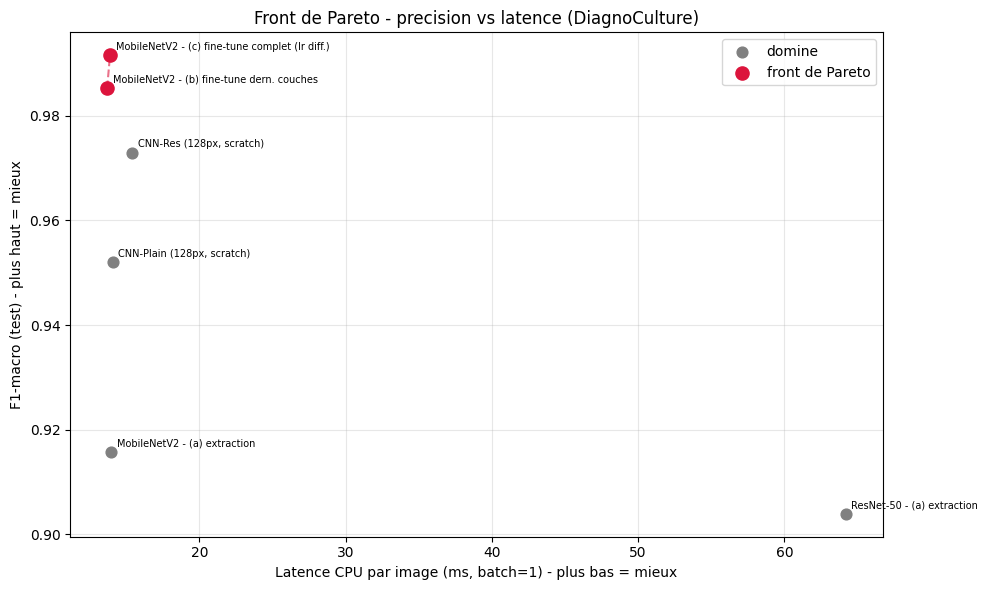

Sur le front : ['MobileNetV2 - (b) fine-tune dern. couches', 'MobileNetV2 - (c) fine-tune complet (lr diff.)']


In [28]:
pts = recap_df.copy()
x = pts["lat_CPU_ms"].values; y = pts["f1_macro"].values; names = pts["modele"].values

is_pareto = np.ones(len(pts), dtype=bool)
for i in range(len(pts)):
    for j in range(len(pts)):
        if (x[j] <= x[i]) and (y[j] >= y[i]) and (x[j] < x[i] or y[j] > y[i]):
            is_pareto[i] = False; break

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(x[~is_pareto], y[~is_pareto], c="gray", s=60, label="domine")
ax.scatter(x[is_pareto],  y[is_pareto],  c="crimson", s=90, label="front de Pareto")
front = pts[is_pareto].sort_values("lat_CPU_ms")
ax.plot(front["lat_CPU_ms"], front["f1_macro"], "--", c="crimson", alpha=.6)
for xi, yi, n in zip(x, y, names):
    ax.annotate(n, (xi, yi), fontsize=7, xytext=(4,4), textcoords="offset points")
ax.set_xlabel("Latence CPU par image (ms, batch=1) - plus bas = mieux")
ax.set_ylabel("F1-macro (test) - plus haut = mieux")
ax.set_title("Front de Pareto - precision vs latence (DiagnoCulture)")
ax.legend(); plt.grid(True, alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(RESULTS, "pareto_transfer.png"), dpi=120, bbox_inches="tight")
plt.show()
print("Sur le front :", list(front["modele"]))

**Interprétation.** Front de Pareto = **MobileNetV2 (b) → MobileNetV2 (c)** : aucun autre modèle n'est à la fois plus précis et plus rapide qu'eux. Dominés : CNN-Plain et CNN-Res (moins précis à latence comparable), MobileNetV2 (a) et ResNet-50 (a). Les modèles légers sont tous groupés en latence CPU (13,7–15,4 ms) → le choix se joue sur la précision. ResNet-50 est doublement dominé (plus lent **et** moins précis).:

### Recommandation — smartphone d'entrée de gamme

**Contrainte.** Un smartphone d'entrée de gamme exécute le modèle **sur CPU** (pas de CUDA),
avec stockage/RAM limités. Les deux métriques décisives sont donc la **latence CPU** et la
**taille (Mo)** ; la latence GPU est hors-sujet pour cette cible.

**Élimination du lourd.** ResNet-50 (extraction) est **dominé** : 71,4 ms CPU (≈4,7× plus lent
que les MobileNet), 94 Mo, et le plus faible F1-macro (0,904). Un gros backbone n'apporte rien
sur ce dataset — à écarter.

**Observation clé.** Sur CPU, tous les modèles légers sont groupés entre **14,6 et 16,1 ms** :
la latence ne les sépare quasiment pas. Le choix se joue donc sur la **précision**.

| Modèle (front de Pareto) | F1-macro | Latence CPU | Taille |
|---|---|---|---|
| MobileNetV2 — (b) dern. couches | 0,985 | 13,7 ms | 8,9 Mo |
| **MobileNetV2 — (c) complet lr diff.** | **0,992** | 13,9 ms | 8,9 Mo |

**Recommandation : MobileNetV2 fine-tuné complètement (lr différencié).**
C'est le meilleur F1-macro (0,992), et le surcoût face au plus rapide est négligeable
(**+1,5 ms, +3,3 Mo**) pour **+1,5 point de F1**. 8,9 Mo tient sans problème dans une app mobile.

**Alternative frugale.** Si le stockage/RAM est très contraint, **CNN-Plain** (Partie 1) reste
imbattable en légèreté (5,6 Mo, 14,6 ms) pour seulement ~1,5 pt de F1 en moins — et sans même
dépendre de poids ImageNet.

**Nuance (pour la soutenance).** Sur GPU, les CNN maison sont en fait **plus rapides**
(1,3 ms vs 5,7 ms) : les convolutions depthwise de MobileNet, économes en opérations (FLOPs),
exploitent mal le parallélisme du GPU (elles sont *memory-bound*). MobileNet optimise le
**nombre d'opérations** (idéal CPU mobile), pas l'intensité arithmétique (idéale GPU). Donc
« léger en FLOPs » ≠ « rapide sur GPU » — ce qui confirme que la métrique pertinente pour un
smartphone est bien la **latence CPU**.